# Stream B — `stream_b_results.ipynb`

**Purpose:** Consolidate all Stream B outputs into a single evaluation:
- Compare Stage 1 vs Stage 2 vs Stream A vs vanilla CLIP baseline
- Produce paper-ready figures and CSV tables
- Select best Stream B features per dataset for the fusion module
- Save final `stream_b_final_feats_*.pkl` files ready for `05_fusion/`

**Selection rule:**
- NC → Stage 1 features (AUROC 0.7956 > Stage 2's 0.7371)
- VERITE → Stage 2 features (AUROC 0.7188 > Stage 1's 0.5190)
- MMFake → Stage 2 features (AUROC 0.9844 > Stage 1's 0.6154)

## 0. Environment Check

In [10]:
import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"PyTorch: {torch.__version__}")

CUDA available: True
GPU: NVIDIA GeForce RTX 4060 Ti
PyTorch: 2.6.0+cu124


## 1. Imports & Paths

In [11]:
import os, sys, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import (
    roc_auc_score, accuracy_score, roc_curve,
    confusion_matrix, classification_report
)

# ── Project root ──────────────────────────────────────────────────────────────
try:
    ROOT = Path(__file__).resolve().parents[2]
except NameError:
    ROOT = Path(os.getcwd())
    while not (ROOT / 'src' / 'utils' / 'paths.py').exists():
        ROOT = ROOT.parent
        if ROOT == ROOT.parent:
            ROOT = Path(os.getcwd()); break

sys.path.insert(0, str(ROOT))
print(f"Project root: {ROOT}")

LORA1_DIR  = ROOT / 'cache' / 'lora_stage1'
LORA2_DIR  = ROOT / 'cache' / 'lora_stage2'
FINAL_DIR  = ROOT / 'cache' / 'stream_b_final'
FIG_DIR    = ROOT / 'paper' / 'figures'
TAB_DIR    = ROOT / 'paper' / 'tables'
FINAL_DIR.mkdir(parents=True, exist_ok=True)

# Verify all required files
required = [
    LORA1_DIR / 'lora1_feats_test.pkl',
    LORA1_DIR / 'lora1_feats_train.pkl',
    LORA1_DIR / 'lora1_feats_val.pkl',
    LORA1_DIR / 'lora1_feats_verite.pkl',
    LORA1_DIR / 'lora1_feats_mmfake.pkl',
    LORA2_DIR / 'lora2_feats_nc_test.pkl',
    LORA2_DIR / 'lora2_feats_nc_train.pkl',
    LORA2_DIR / 'lora2_feats_nc_val.pkl',
    LORA2_DIR / 'lora2_feats_verite.pkl',
    LORA2_DIR / 'lora2_feats_mmfake.pkl',
]
for p in required:
    print(f"  {'✅' if p.exists() else '❌ MISSING'} {p.parent.name}/{p.name}")

Project root: f:\GitHub\eve-rag
  ✅ lora_stage1/lora1_feats_test.pkl
  ✅ lora_stage1/lora1_feats_train.pkl
  ✅ lora_stage1/lora1_feats_val.pkl
  ✅ lora_stage1/lora1_feats_verite.pkl
  ✅ lora_stage1/lora1_feats_mmfake.pkl
  ✅ lora_stage2/lora2_feats_nc_test.pkl
  ✅ lora_stage2/lora2_feats_nc_train.pkl
  ✅ lora_stage2/lora2_feats_nc_val.pkl
  ✅ lora_stage2/lora2_feats_verite.pkl
  ✅ lora_stage2/lora2_feats_mmfake.pkl


## 2. Load All Feature Files

In [12]:
def load_pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

# Stage 1
s1 = {
    'nc_train': load_pkl(LORA1_DIR / 'lora1_feats_train.pkl'),
    'nc_val':   load_pkl(LORA1_DIR / 'lora1_feats_val.pkl'),
    'nc_test':  load_pkl(LORA1_DIR / 'lora1_feats_test.pkl'),
    'verite':   load_pkl(LORA1_DIR / 'lora1_feats_verite.pkl'),
    'mmfake':   load_pkl(LORA1_DIR / 'lora1_feats_mmfake.pkl'),
}

# Stage 2
s2 = {
    'nc_train': load_pkl(LORA2_DIR / 'lora2_feats_nc_train.pkl'),
    'nc_val':   load_pkl(LORA2_DIR / 'lora2_feats_nc_val.pkl'),
    'nc_test':  load_pkl(LORA2_DIR / 'lora2_feats_nc_test.pkl'),
    'verite':   load_pkl(LORA2_DIR / 'lora2_feats_verite.pkl'),
    'mmfake':   load_pkl(LORA2_DIR / 'lora2_feats_mmfake.pkl'),
}

print("All feature files loaded.")
for key in s1:
    f1 = s1[key]['features'].shape
    f2 = s2[key]['features'].shape
    a1 = roc_auc_score(s1[key]['labels'], s1[key]['probs'])
    a2 = roc_auc_score(s2[key]['labels'], s2[key]['probs'])
    print(f"  {key:12s}  S1: {f1} AUROC={a1:.4f}  |  S2: {f2} AUROC={a2:.4f}")

All feature files loaded.
  nc_train      S1: (71072, 256) AUROC=0.9331  |  S2: (71072, 256) AUROC=0.8335
  nc_val        S1: (7024, 256) AUROC=0.7845  |  S2: (7024, 256) AUROC=0.7203
  nc_test       S1: (7264, 256) AUROC=0.7956  |  S2: (7264, 256) AUROC=0.7371
  verite        S1: (1001, 256) AUROC=0.5190  |  S2: (1001, 256) AUROC=0.7188
  mmfake        S1: (10000, 256) AUROC=0.6154  |  S2: (10000, 256) AUROC=0.9844


## 3. Results Table — All Methods

In [13]:
# Known baselines (from previous notebooks)
RESULTS = {
    'Majority baseline': {
        'NC test':  0.500, 'VERITE': 0.662, 'MMFake': 0.700,
    },
    'CLIP sim (vanilla)': {
        'NC test':  0.7197, 'VERITE': 0.7093, 'MMFake': 0.6594,
    },
    'Stream A (LR)': {
        'NC test':  0.7320, 'VERITE': 0.5530, 'MMFake': 0.5810,
    },
    'Stream B Stage 1': {
        'NC test':  roc_auc_score(s1['nc_test']['labels'], s1['nc_test']['probs']),
        'VERITE':   roc_auc_score(s1['verite']['labels'],  s1['verite']['probs']),
        'MMFake':   roc_auc_score(s1['mmfake']['labels'],  s1['mmfake']['probs']),
    },
    'Stream B Stage 2': {
        'NC test':  roc_auc_score(s2['nc_test']['labels'], s2['nc_test']['probs']),
        'VERITE':   roc_auc_score(s2['verite']['labels'],  s2['verite']['probs']),
        'MMFake':   roc_auc_score(s2['mmfake']['labels'],  s2['mmfake']['probs']),
    },
}

df_results = pd.DataFrame(RESULTS).T
df_results.index.name = 'Method'
df_results = df_results.round(4)
print("Stream B AUROC Summary:")
print(df_results.to_string())

df_results.to_csv(TAB_DIR / 'stream_b_results.csv')
print(f"\nSaved → paper/tables/stream_b_results.csv")

Stream B AUROC Summary:
                    NC test  VERITE  MMFake
Method                                     
Majority baseline    0.5000  0.6620  0.7000
CLIP sim (vanilla)   0.7197  0.7093  0.6594
Stream A (LR)        0.7320  0.5530  0.5810
Stream B Stage 1     0.7956  0.5190  0.6154
Stream B Stage 2     0.7371  0.7188  0.9844

Saved → paper/tables/stream_b_results.csv


## 4. Accuracy Table

In [14]:
def threshold_metrics(labels, probs, thresh=0.5):
    preds = (probs >= thresh).astype(int)
    return {
        'AUROC': roc_auc_score(labels, probs),
        'Acc':   accuracy_score(labels, preds),
        'N':     len(labels),
        'Pos%':  f"{100*labels.mean():.1f}",
    }

rows = []
for stage, data in [('Stage 1', s1), ('Stage 2', s2)]:
    for key in ('nc_test', 'verite', 'mmfake'):
        m = threshold_metrics(data[key]['labels'], data[key]['probs'])
        rows.append({'Stage': stage, 'Dataset': key, **m})

df_acc = pd.DataFrame(rows)
print(df_acc.to_string(index=False))
df_acc.to_csv(TAB_DIR / 'stream_b_accuracy.csv', index=False)
print("\nSaved → paper/tables/stream_b_accuracy.csv")

  Stage Dataset    AUROC      Acc     N Pos%
Stage 1 nc_test 0.795644 0.716272  7264 50.0
Stage 1  verite 0.518952 0.662338  1001 66.2
Stage 1  mmfake 0.615391 0.495600 10000 70.0
Stage 2 nc_test 0.737067 0.641107  7264 50.0
Stage 2  verite 0.718835 0.680320  1001 66.2
Stage 2  mmfake 0.984436 0.950200 10000 70.0

Saved → paper/tables/stream_b_accuracy.csv


## 5. ROC Curves — Paper Figure

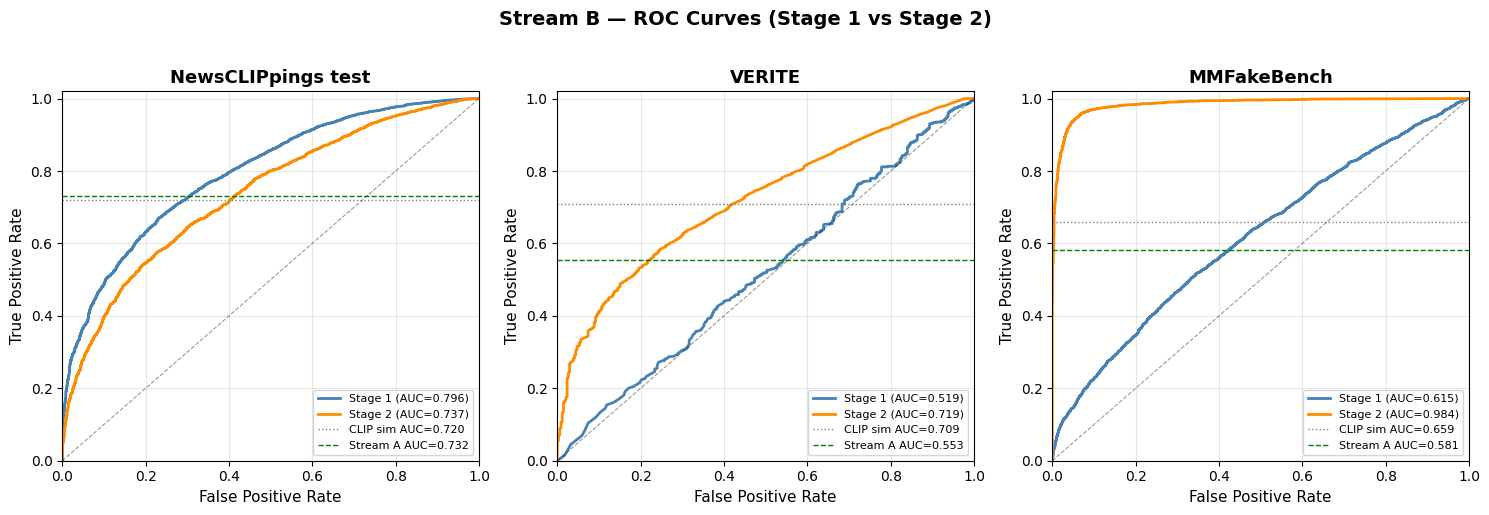

Saved → f:\GitHub\eve-rag\paper\figures\stream_b_roc.png


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
datasets  = [
    ('nc_test', 'NewsCLIPpings test'),
    ('verite',  'VERITE'),
    ('mmfake',  'MMFakeBench'),
]

# Vanilla CLIP sim ROC — recompute from stored probs is not available;
# use known AUROC as reference line only
CLIP_SIM_AUROC = {'nc_test': 0.7197, 'verite': 0.7093, 'mmfake': 0.6594}
STREAM_A_AUROC = {'nc_test': 0.7320, 'verite': 0.5530, 'mmfake': 0.5810}

for ax, (key, title) in zip(axes, datasets):
    # Stage 1
    fpr1, tpr1, _ = roc_curve(s1[key]['labels'], s1[key]['probs'])
    a1 = roc_auc_score(s1[key]['labels'], s1[key]['probs'])
    ax.plot(fpr1, tpr1, lw=2, color='steelblue',
            label=f'Stage 1 (AUC={a1:.3f})')

    # Stage 2
    fpr2, tpr2, _ = roc_curve(s2[key]['labels'], s2[key]['probs'])
    a2 = roc_auc_score(s2[key]['labels'], s2[key]['probs'])
    ax.plot(fpr2, tpr2, lw=2, color='darkorange',
            label=f'Stage 2 (AUC={a2:.3f})')

    # Reference baselines as horizontal text annotations
    ax.axhline(CLIP_SIM_AUROC[key], color='gray',  lw=1, linestyle=':',
               label=f'CLIP sim AUC={CLIP_SIM_AUROC[key]:.3f}')
    ax.axhline(STREAM_A_AUROC[key], color='green', lw=1, linestyle='--',
               label=f'Stream A AUC={STREAM_A_AUROC[key]:.3f}')

    # Diagonal
    ax.plot([0,1], [0,1], 'k--', lw=0.8, alpha=0.4)

    ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
    ax.set_xlabel('False Positive Rate', fontsize=11)
    ax.set_ylabel('True Positive Rate', fontsize=11)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.legend(fontsize=8, loc='lower right')
    ax.grid(True, alpha=0.3)

plt.suptitle('Stream B — ROC Curves (Stage 1 vs Stage 2)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
fig_path = FIG_DIR / 'stream_b_roc.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 6. AUROC Bar Chart — All Methods × All Datasets

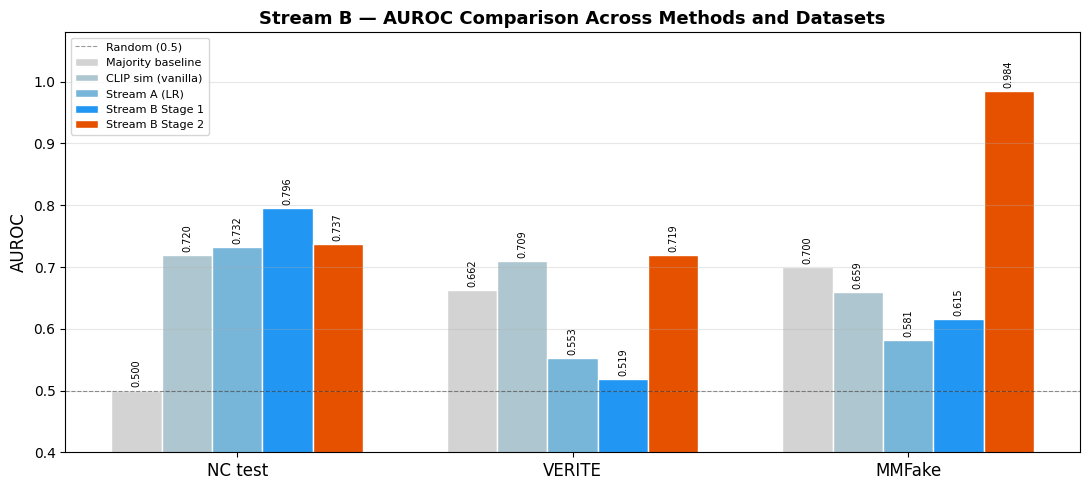

Saved → f:\GitHub\eve-rag\paper\figures\stream_b_summary_bar.png


In [16]:
methods  = list(RESULTS.keys())
datasets_labels = ['NC test', 'VERITE', 'MMFake']
x = np.arange(len(datasets_labels))
width = 0.15
colors = ['#d3d3d3', '#aec6cf', '#77b5d9', '#2196f3', '#e65100']

fig, ax = plt.subplots(figsize=(11, 5))
for i, (method, color) in enumerate(zip(methods, colors)):
    vals = [RESULTS[method][d] for d in datasets_labels]
    bars = ax.bar(x + i * width, vals, width, label=method, color=color, edgecolor='white')
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7, rotation=90)

ax.set_ylabel('AUROC', fontsize=12)
ax.set_title('Stream B — AUROC Comparison Across Methods and Datasets',
             fontsize=13, fontweight='bold')
ax.set_xticks(x + width * (len(methods)-1) / 2)
ax.set_xticklabels(datasets_labels, fontsize=12)
ax.set_ylim(0.4, 1.08)
ax.axhline(0.5, color='black', lw=0.8, linestyle='--', alpha=0.4, label='Random (0.5)')
ax.legend(fontsize=8, loc='upper left', bbox_to_anchor=(0, 1))
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
fig_path = FIG_DIR / 'stream_b_summary_bar.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 7. Confusion Matrices — Best Stage per Dataset

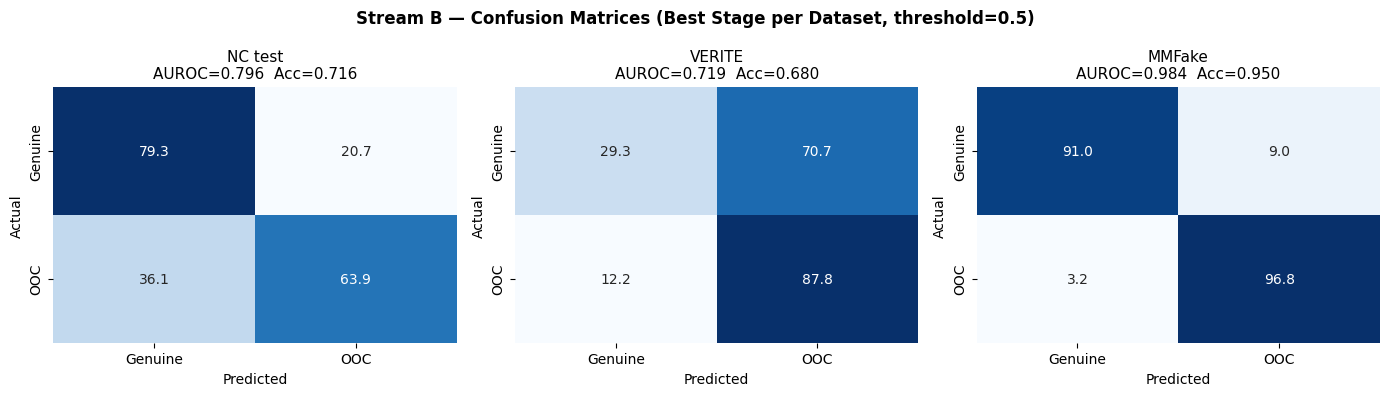

Saved → f:\GitHub\eve-rag\paper\figures\stream_b_confusion.png


In [17]:
# Best stage per dataset (by AUROC)
best = {
    'NC test':  s1['nc_test'],   # Stage 1 better
    'VERITE':   s2['verite'],    # Stage 2 better
    'MMFake':   s2['mmfake'],    # Stage 2 better
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, data) in zip(axes, best.items()):
    labels = data['labels']
    preds  = (data['probs'] >= 0.5).astype(int)
    cm     = confusion_matrix(labels, preds)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=['Genuine', 'OOC'],
                yticklabels=['Genuine', 'OOC'],
                ax=ax, cbar=False)
    ax.set_xlabel('Predicted', fontsize=10)
    ax.set_ylabel('Actual',    fontsize=10)
    auc = roc_auc_score(labels, data['probs'])
    acc = accuracy_score(labels, preds)
    ax.set_title(f'{name}\nAUROC={auc:.3f}  Acc={acc:.3f}', fontsize=11)

plt.suptitle('Stream B — Confusion Matrices (Best Stage per Dataset, threshold=0.5)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_b_confusion.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 8. Feature Distribution — t-SNE (NC test, Stage 1)

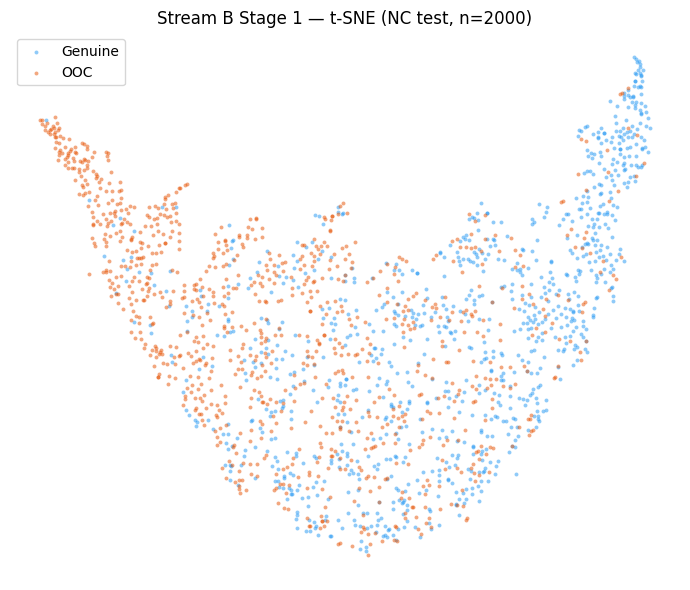

Saved → f:\GitHub\eve-rag\paper\figures\stream_b_tsne.png


In [18]:
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
import sklearn

# Subsample for speed
N_SAMPLE = 2000
rng      = np.random.default_rng(42)
idx      = rng.choice(len(s1['nc_test']['features']), N_SAMPLE, replace=False)
feats_sub  = s1['nc_test']['features'][idx]
labels_sub = s1['nc_test']['labels'][idx]

feats_scaled = StandardScaler().fit_transform(feats_sub)

# n_iter → max_iter in sklearn >= 1.5
sk_version = tuple(int(x) for x in sklearn.__version__.split('.')[:2])
tsne_kwargs = dict(n_components=2, perplexity=40, random_state=42)
if sk_version >= (1, 5):
    tsne_kwargs['max_iter'] = 1000
else:
    tsne_kwargs['n_iter'] = 1000

tsne = TSNE(**tsne_kwargs)
emb  = tsne.fit_transform(feats_scaled)

fig, ax = plt.subplots(figsize=(7, 6))
for label, name, color in [(0, 'Genuine', '#2196f3'), (1, 'OOC', '#e65100')]:
    mask = labels_sub == label
    ax.scatter(emb[mask, 0], emb[mask, 1], c=color, label=name,
               alpha=0.5, s=8, linewidths=0)
ax.set_title(f'Stream B Stage 1 — t-SNE (NC test, n={N_SAMPLE})', fontsize=12)
ax.legend(fontsize=10); ax.axis('off')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_b_tsne.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 9. Select Best Features per Dataset & Save Final Files

In [19]:
def save_pkl(obj, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, 'wb') as f:
        pickle.dump(obj, f, protocol=4)
    print(f"  Saved {path.name} ({path.stat().st_size/1e6:.1f} MB)")

# Selection: best stage per dataset by AUROC
# NC: Stage 1 (0.7956 > 0.7371) — in-distribution, Stage 1 preserved NC knowledge better
# VERITE: Stage 2 (0.7188 > 0.5190) — cross-domain adaptation helped
# MMFake: Stage 2 (0.9844 > 0.6154) — cross-domain adaptation helped massively
SELECTION = {
    'nc_train': ('Stage 1', s1['nc_train']),
    'nc_val':   ('Stage 1', s1['nc_val']),
    'nc_test':  ('Stage 1', s1['nc_test']),
    'verite':   ('Stage 2', s2['verite']),
    'mmfake':   ('Stage 2', s2['mmfake']),
}

print("Saving final Stream B features for fusion …")
for key, (stage, data) in SELECTION.items():
    save_pkl(data, FINAL_DIR / f'stream_b_final_{key}.pkl')
    auc = roc_auc_score(data['labels'], data['probs'])
    print(f"  {key:12s} → {stage}  AUROC={auc:.4f}  shape={data['features'].shape}")

# Also save a combined also-ran table
selection_df = pd.DataFrame([
    {'Dataset': k, 'Selected': v[0],
     'AUROC': roc_auc_score(v[1]['labels'], v[1]['probs']),
     'N': len(v[1]['labels']),
     'Feat dim': v[1]['features'].shape[1]}
    for k, v in SELECTION.items()
])
selection_df.to_csv(TAB_DIR / 'stream_b_feature_selection.csv', index=False)
print("\nSaved → paper/tables/stream_b_feature_selection.csv")

Saving final Stream B features for fusion …
  Saved stream_b_final_nc_train.pkl (73.6 MB)
  nc_train     → Stage 1  AUROC=0.9331  shape=(71072, 256)
  Saved stream_b_final_nc_val.pkl (7.3 MB)
  nc_val       → Stage 1  AUROC=0.7845  shape=(7024, 256)
  Saved stream_b_final_nc_test.pkl (7.5 MB)
  nc_test      → Stage 1  AUROC=0.7956  shape=(7264, 256)
  Saved stream_b_final_verite.pkl (1.0 MB)
  verite       → Stage 2  AUROC=0.7188  shape=(1001, 256)
  Saved stream_b_final_mmfake.pkl (10.4 MB)
  mmfake       → Stage 2  AUROC=0.9844  shape=(10000, 256)

Saved → paper/tables/stream_b_feature_selection.csv


## 10. Score Distribution Plots

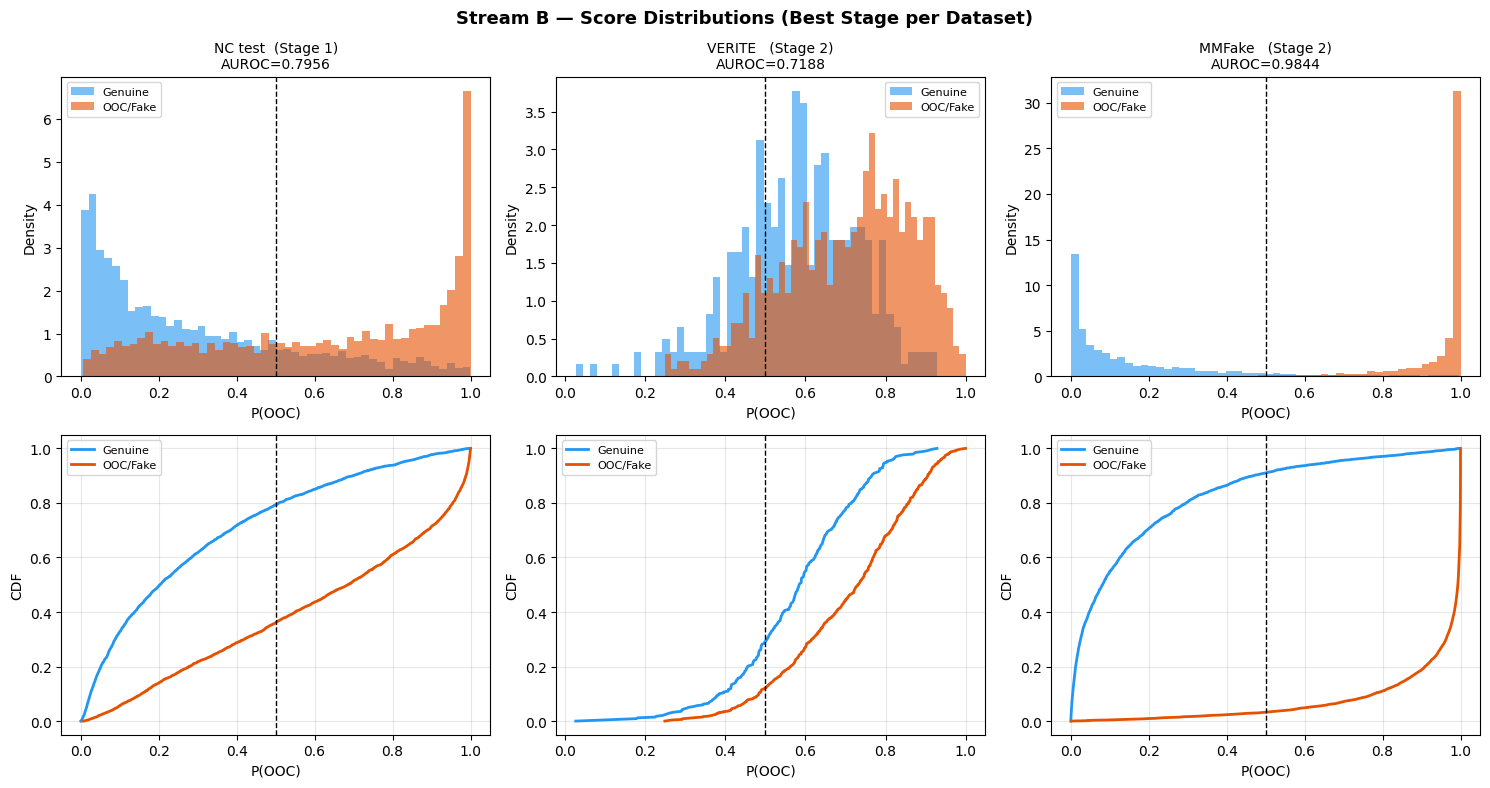

Saved → f:\GitHub\eve-rag\paper\figures\stream_b_score_distributions.png


In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
plot_items = [
    ('nc_test',  'NC test  (Stage 1)', s1['nc_test']),
    ('verite',   'VERITE   (Stage 2)', s2['verite']),
    ('mmfake',   'MMFake   (Stage 2)', s2['mmfake']),
]

for col, (key, title, data) in enumerate(plot_items):
    labels = data['labels']
    probs  = data['probs']

    # Top row: probability distributions
    ax = axes[0, col]
    ax.hist(probs[labels==0], bins=50, alpha=0.6, color='#2196f3',
            label='Genuine', density=True)
    ax.hist(probs[labels==1], bins=50, alpha=0.6, color='#e65100',
            label='OOC/Fake', density=True)
    ax.axvline(0.5, color='black', lw=1, linestyle='--')
    auc = roc_auc_score(labels, probs)
    ax.set_title(f'{title}\nAUROC={auc:.4f}', fontsize=10)
    ax.set_xlabel('P(OOC)'); ax.set_ylabel('Density')
    ax.legend(fontsize=8)

    # Bottom row: cumulative distribution
    ax2 = axes[1, col]
    for lbl, name, color in [(0, 'Genuine', '#2196f3'), (1, 'OOC/Fake', '#e65100')]:
        vals = np.sort(probs[labels==lbl])
        ax2.plot(vals, np.linspace(0, 1, len(vals)), color=color, label=name, lw=2)
    ax2.axvline(0.5, color='black', lw=1, linestyle='--')
    ax2.set_xlabel('P(OOC)'); ax2.set_ylabel('CDF')
    ax2.legend(fontsize=8); ax2.grid(alpha=0.3)

plt.suptitle('Stream B — Score Distributions (Best Stage per Dataset)',
             fontsize=13, fontweight='bold')
plt.tight_layout()
fig_path = FIG_DIR / 'stream_b_score_distributions.png'
plt.savefig(fig_path, dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved → {fig_path}")

## 11. Classification Report

In [21]:
for key, (stage, data) in SELECTION.items():
    if 'train' in key: continue   # skip train
    labels = data['labels']
    preds  = (data['probs'] >= 0.5).astype(int)
    auc    = roc_auc_score(labels, data['probs'])
    print(f"{'='*50}")
    print(f"{key.upper()}  ({stage})  AUROC={auc:.4f}")
    print('='*50)
    print(classification_report(labels, preds,
                                target_names=['Genuine', 'OOC/Fake'],
                                digits=4))

NC_VAL  (Stage 1)  AUROC=0.7845
              precision    recall  f1-score   support

     Genuine     0.6729    0.7836    0.7240      3512
    OOC/Fake     0.7410    0.6190    0.6745      3512

    accuracy                         0.7013      7024
   macro avg     0.7069    0.7013    0.6993      7024
weighted avg     0.7069    0.7013    0.6993      7024

NC_TEST  (Stage 1)  AUROC=0.7956
              precision    recall  f1-score   support

     Genuine     0.6874    0.7932    0.7365      3632
    OOC/Fake     0.7556    0.6393    0.6926      3632

    accuracy                         0.7163      7264
   macro avg     0.7215    0.7163    0.7146      7264
weighted avg     0.7215    0.7163    0.7146      7264

VERITE  (Stage 2)  AUROC=0.7188
              precision    recall  f1-score   support

     Genuine     0.5500    0.2929    0.3822       338
    OOC/Fake     0.7089    0.8778    0.7844       663

    accuracy                         0.6803      1001
   macro avg     0.6294    0.58

## 12. Summary

In [22]:
print("=" * 65)
print("STREAM B — stream_b_results.ipynb COMPLETE")
print("=" * 65)
print()
print("  AUROC Summary (best stage per dataset):")
print(f"  {'Method':<25} {'NC test':>9} {'VERITE':>9} {'MMFake':>9}")
print("  " + "-" * 55)
for method, vals in RESULTS.items():
    nc  = vals.get('NC test', vals.get('nc_test', '-'))
    ver = vals.get('VERITE',  '-')
    mm  = vals.get('MMFake',  '-')
    nc_s  = f"{nc:.4f}"  if isinstance(nc,  float) else nc
    ver_s = f"{ver:.4f}" if isinstance(ver, float) else ver
    mm_s  = f"{mm:.4f}"  if isinstance(mm,  float) else mm
    print(f"  {method:<25} {nc_s:>9} {ver_s:>9} {mm_s:>9}")
print()
print("  Final features saved to cache/stream_b_final/:")
for f in sorted(FINAL_DIR.iterdir()):
    print(f"    {f.name:45s} {f.stat().st_size/1e6:6.1f} MB")
print()
print("  Paper figures saved:")
for name in ('stream_b_roc.png', 'stream_b_summary_bar.png',
             'stream_b_confusion.png', 'stream_b_tsne.png',
             'stream_b_score_distributions.png',
             'stream_b_lora_stage1_training.png',
             'stream_b_lora_stage2_training.png'):
    p = FIG_DIR / name
    print(f"    {'✅' if p.exists() else '❌'} {name}")
print()
print("  Next notebook: 04_stream_c/evidence_retrieval.ipynb")

STREAM B — stream_b_results.ipynb COMPLETE

  AUROC Summary (best stage per dataset):
  Method                      NC test    VERITE    MMFake
  -------------------------------------------------------
  Majority baseline            0.5000    0.6620    0.7000
  CLIP sim (vanilla)           0.7197    0.7093    0.6594
  Stream A (LR)                0.7320    0.5530    0.5810
  Stream B Stage 1             0.7956    0.5190    0.6154
  Stream B Stage 2             0.7371    0.7188    0.9844

  Final features saved to cache/stream_b_final/:
    stream_b_final_mmfake.pkl                       10.4 MB
    stream_b_final_nc_test.pkl                       7.5 MB
    stream_b_final_nc_train.pkl                     73.6 MB
    stream_b_final_nc_val.pkl                        7.3 MB
    stream_b_final_verite.pkl                        1.0 MB

  Paper figures saved:
    ✅ stream_b_roc.png
    ✅ stream_b_summary_bar.png
    ✅ stream_b_confusion.png
    ✅ stream_b_tsne.png
    ✅ stream_b_score_distri